# Object Detection with YOLO — Set 9

*   Object Detection
*   YOLO for Object Detection
    * Dataset formats
    * Fine-tuning with a custom dataset

**Tasks of Set 9 (from the slides)**

| # | Task | Section |
|---|------|---------|
| 9.1 | Load a pretrained Ultralytics model and run it on an image (+ *"Why are people blue?"*) | [9.1](#set-9.1) |
| 9.2 | COCO → YOLO conversion (`coco_to_yolo`), `data.yaml`, data exploration, **train YOLO on blood-cell data and save it** | [9.2](#set-9.2) |
| 9.3 | Load the saved model, test on unseen images, **visualize GT and predicted bboxes**, quantitative evaluation (PR, FPPI, mAP) | [9.3](#set-9.3) |
| + | Optional extras: conversion check, per-class histograms, cell counting, activation maps | [Extras](#extras) |

**How to run:** Colab with a GPU (*Runtime → Change runtime type → T4 GPU*) is recommended for training
(50 epochs ≈ 1 h on a T4). Locally everything also runs on CPU, but training is slow — use `QUICK_TEST = True` to check the pipeline.
Sections 9.3 and Extras only need the saved weights, so after training you can restart and run *Setup → 9.2 data prep → 9.3*.

# YOLO for Object Detection

*   There are several open source implementations of each version of YOLO.
*   For this exercise, we will not be implementing the YOLO from scratch as it is a challenging model and requires many customized elements.
*   We will use the official Ultralytics YOLO11 implementation for this exercise.
*  The Ultralytics YOLO implementation is available as a Python package that can be installed via pip.

In [1]:
# Setup: install Ultralytics if missing (works in Colab and in a local kernel)
import sys, os
IN_COLAB = "google.colab" in sys.modules
try:
    import ultralytics
except ImportError:
    %pip install -q ultralytics
    import ultralytics
ultralytics.checks()

Ultralytics 8.4.216  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4090 Laptop GPU, 16376MiB)


Setup complete  (32 CPUs, 31.7 GB RAM, 584.3/951.6 GB disk)


In [2]:
# Paths & global config — the only cell you should need to edit
from pathlib import Path
import torch

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO")  # upload blood_cell.v1i.coco.zip here
    DATA_DIR = Path("/content/data")      # Colab local disk: much faster than Drive for ~3.5k small files
else:
    PROJECT_DIR = Path.cwd()              # the notebooks/ folder (where the zips are)
    DATA_DIR = PROJECT_DIR / "data"

COCO_ZIP = PROJECT_DIR / "blood_cell.v1i.coco.zip"
ROBOFLOW_YOLO_ZIP = PROJECT_DIR / "blood cell.v1i.yolov11.zip"   # only used in the extras (sanity check)
COCO_ROOT = DATA_DIR / "blood_cell.v1i.coco"
YOLO_ROOT = DATA_DIR / "blood_cell.v1i.yolov11"
DATA_YAML = YOLO_ROOT / "data.yaml"
RUNS_DIR = PROJECT_DIR / "runs" / "detect"   # persisted (on Drive in Colab), so logs survive a runtime restart
MODELS_DIR = PROJECT_DIR / "models"          # where the trained model is saved (Set 9.2 "... and save")

DEVICE = 0 if torch.cuda.is_available() else "cpu"
CLASS_NAMES = ["PC", "RBC", "WBC"]
CLASS_COLORS = {"PC": "red", "RBC": "green", "WBC": "blue"}   # same colours as in the slides
print(f"PROJECT_DIR={PROJECT_DIR}\nDATA_DIR={DATA_DIR}\nDEVICE={DEVICE}")

PROJECT_DIR=C:\Users\sonia\Documents\master\MasterLabs\CV
DATA_DIR=C:\Users\sonia\Documents\master\MasterLabs\CV\data
DEVICE=0


In [3]:
# Small helpers reused across the notebook
import json, random, shutil, time
from collections import Counter, defaultdict
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd


def read_rgb(path):
    """cv2 reads BGR -> convert to RGB for matplotlib."""
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def read_yolo_labels(label_path, W, H):
    """YOLO txt (cls xc yc w h, normalised) -> (classes [N], boxes xyxy in pixels [N,4])."""
    label_path = Path(label_path)
    rows = [l.split() for l in label_path.read_text().splitlines() if l.strip()] if label_path.exists() else []
    if not rows:
        return np.zeros(0, int), np.zeros((0, 4))
    a = np.array(rows, dtype=float)
    xc, yc, w, h = a[:, 1] * W, a[:, 2] * H, a[:, 3] * W, a[:, 4] * H
    return a[:, 0].astype(int), np.stack([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2], axis=1)


def draw_boxes(ax, boxes_xyxy, classes, scores=None, ls="-", lw=1.5, text=True, names=CLASS_NAMES):
    """Draw xyxy boxes coloured by class (PC red, RBC green, WBC blue)."""
    for k, ((x1, y1, x2, y2), c) in enumerate(zip(boxes_xyxy, classes)):
        color = CLASS_COLORS[names[int(c)]]
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=lw, linestyle=ls))
        if text:
            label = names[int(c)] + (f" {scores[k]:.2f}" if scores is not None else "")
            ax.text(x1, y1, label, color=color, fontsize=8, va="bottom")


def label_path_for(image_path):
    """<split>/images/x.jpg -> <split>/labels/x.txt"""
    image_path = Path(image_path)
    return image_path.parent.parent / "labels" / (image_path.stem + ".txt")

<a id="set-9.1"></a>
# Set 9.1 — Load a pretrained Ultralytics model and run it on an image

`yolo11n.pt` is YOLO11-nano pretrained on the 80-class COCO dataset (`yolo11n.yaml` would build the same
architecture with random weights — we use that later for training from scratch).

In [4]:
from ultralytics import YOLO

# Load a model
# model = YOLO('yolo11n.yaml')  # build a new model from scratch
pretrained = YOLO("yolo11n.pt")  # load a pretrained model (recommended for training)
# Use the model
results = pretrained("https://ultralytics.com/images/bus.jpg")  # predict on an image

image 1/1 C:\Users\sonia\Documents\master\MasterLabs\CV\bus.jpg: 640x480 4 persons, 1 bus, 16.9ms


Speed: 95.5ms preprocess, 16.9ms inference, 17.4ms postprocess per image at shape (1, 3, 640, 480)


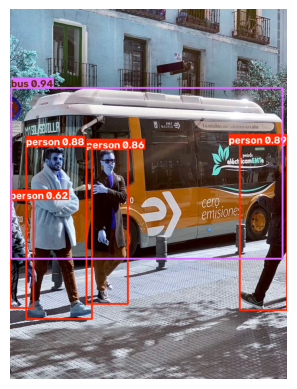

In [5]:
# Exactly as in the slide
plt.imshow(results[0].plot())
plt.axis("off")
plt.show()

### Why are people blue?

`results[0].plot()` returns the annotated image as a NumPy array in **BGR** channel order — Ultralytics uses OpenCV
(`cv2.imread`), and OpenCV stores pixels as B, G, R. `plt.imshow` assumes **RGB**, so the red and blue channels are swapped:
skin tones and the beige coat turn bluish, the yellow façade turns light blue, and the (really blue) EMT bus turns orange.
The drawn boxes are swapped too: the *person* boxes, which Ultralytics draws in blue, appear red in the left panel.

**Fix:** reverse the channel axis (`img[..., ::-1]`) or `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`
(`results[0].orig_img` is BGR as well). Alternatively `results[0].show()` / `results[0].plot(pil=True)` handle the conversion.

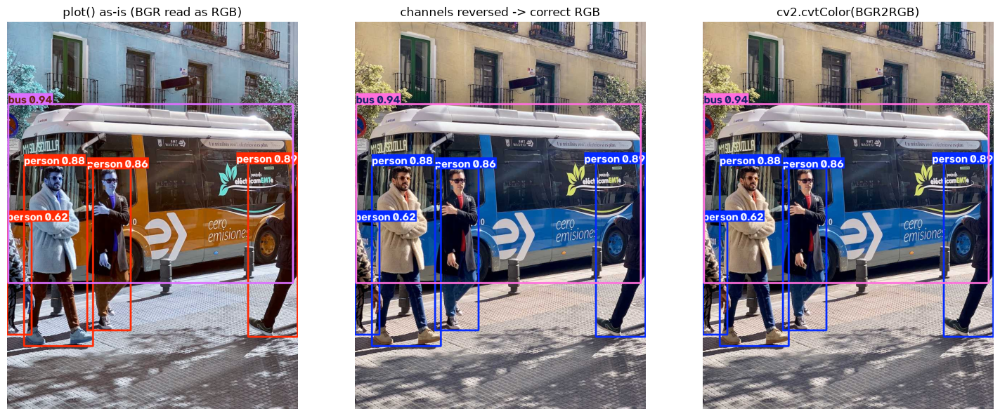

In [6]:
bgr = results[0].plot()
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
ax[0].imshow(bgr);                                   ax[0].set_title("plot() as-is (BGR read as RGB)")
ax[1].imshow(bgr[..., ::-1]);                        ax[1].set_title("channels reversed -> correct RGB")
ax[2].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB));  ax[2].set_title("cv2.cvtColor(BGR2RGB)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Understanding the `Results` and `Boxes` objects

In [7]:
r = results[0]
print(type(r).__name__, "| image (H, W, C):", r.orig_img.shape, "| #classes:", len(r.names))
print("first classes:", dict(list(r.names.items())[:6]))
b = r.boxes
print(type(b).__name__, "with", len(b), "boxes")
print(pd.DataFrame({
    "class": [r.names[int(c)] for c in b.cls],
    "conf": b.conf.cpu().numpy().round(3),
    "x1": b.xyxy[:, 0].cpu().numpy().round(1), "y1": b.xyxy[:, 1].cpu().numpy().round(1),
    "x2": b.xyxy[:, 2].cpu().numpy().round(1), "y2": b.xyxy[:, 3].cpu().numpy().round(1),
}))
print("Same boxes as centre/size (xywh):\n", b.xywh.cpu().numpy().round(1))
print("...and normalised to [0,1] (xywhn, i.e. the YOLO label format):\n", b.xywhn.cpu().numpy().round(3))

Results | image (H, W, C): (1080, 810, 3) | #classes: 80
first classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus'}
Boxes with 5 boxes
    class   conf          x1          y1          x2          y2
0     bus  0.940    3.800000  229.399994  796.200012  728.400024
1  person  0.888  671.000000  394.799988  809.799988  878.700012
2  person  0.878   47.400002  399.600006  239.300003  904.200012
3  person  0.856  223.100006  408.700012  344.500000  860.400024
4  person  0.622    0.000000  556.099976   68.900002  872.400024
Same boxes as centre/size (xywh):
 [[        400       478.9       792.4       499.1]
 [      740.4       636.8       138.8       483.9]
 [      143.4       651.9       191.9       504.6]
 [      283.8       634.6       121.4       451.8]
 [       34.4       714.2        68.8       316.3]]
...and normalised to [0,1] (xywhn, i.e. the YOLO label format):
 [[      0.494       0.443       0.978       0.462]
 [      0.914        0.59       

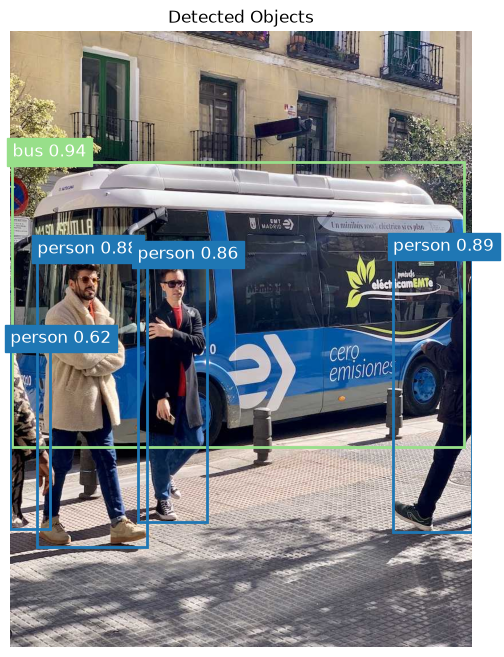

In [8]:
# Plotting the results in a more customizable way can be done using matplotlib by accessing
# the boxes and labels from the results object.
boxes = results[0].boxes
labels = results[0].names

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.imshow(cv2.cvtColor(results[0].orig_img, cv2.COLOR_BGR2RGB))

# define a color map for different classes
colors = matplotlib.colormaps.get_cmap("tab20")

# plot each box
for box in boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu()
    conf = box.conf[0].cpu()
    cls = int(box.cls[0])
    label = labels[cls]

    # create a rectangle patch
    rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor=colors(cls), facecolor="none")
    ax.add_patch(rect)
    ax.text(x1, y1 - 10, f"{label} {conf:.2f}", color="white", fontsize=12, backgroundcolor=colors(cls))

plt.axis("off")
plt.title("Detected Objects")
plt.show()

<a id="set-9.2"></a>
# Set 9.2 — Train a YOLO model on blood cell detection data and save it

*   In this exercise, we will train a YOLO model on a custom dataset.
*   We will prepare the dataset in the required format.
*   We will customize the YOLO model configuration to fit our dataset.

We will use RoboFlow's blood cell detection dataset for this exercise:
https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na

This dataset contains microscopic images of different cells:

* PC - Platelets / Thrombocytes - Small, non-nucleated blood cells essential for hemostasis (stopping bleeding). They clump together to form a plug at the site of a damaged blood vessel wall.
* RBC - Red Blood Cells / Erythrocytes - The most abundant blood cells, responsible for transporting oxygen from the lungs to the body's tissues and carrying carbon dioxide back to the lungs.
* WBC - White Blood Cells / Leukocytes - These cells are the core components of the immune system, defending the body against infections, foreign invaders (bacteria, viruses), and abnormal cells.

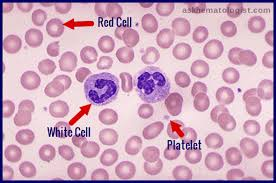

Reference:
```
@misc{
    blood-cell-st9na_dataset,
    title = { blood cell Dataset },
    type = { Open Source Dataset },
    author = { tumor },
    howpublished = { \url{ https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na } },
    url = { https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na },
    journal = { Roboflow Universe },
    publisher = { Roboflow },
    year = { 2024 },
    month = { sep },
    note = { visited on 2025-11-17 },
    }

```

### Understanding the COCO and YOLO dataset formats

In [9]:
# COCO format annotation example
dummy_coco_annotation = {
    "images": [
        {
            "id": 1,
            "width": 640,
            "height": 480,
            "file_name": "image1.jpg"
        },
        {
            "id": 2,
            "width": 800,
            "height": 600,
            "file_name": "image2.jpg"
        }
    ],
    "annotations": [
        {
            "id": 1,
            "image_id": 1,
            "category_id": 1,
            "bbox": [100, 150, 200, 300],  # [x, y, width, height]
            "area": 60000,
            "iscrowd": 0
        },
        {
            "id": 2,
            "image_id": 2,
            "category_id": 1,
            "bbox": [50, 75, 100, 150],
            "area": 15000,
            "iscrowd": 0
        },
        {
            "id": 3,
            "image_id": 2,
            "category_id": 2,
            "bbox": [300, 400, 120, 180],
            "area": 5000,
            "iscrowd": 0
        }
    ],
    "categories": [
        {
            "id": 1,
            "name": "person"
        },
        {
            "id": 2,
            "name": "dog"
        }
    ]
}

YOLO expects the data to be in a different format:

```
├── data.yaml
├── test
│   ├── images
│   │   ├── 018239dc-02bb-5c9c-be33-0737ee53d592_jpg.rf.53258de6e413c4f33f824fb33c5883a3.jpg
│   └── labels
│       ├── 018239dc-02bb-5c9c-be33-0737ee53d592_jpg.rf.53258de6e413c4f33f824fb33c5883a3.txt
├── train
│   ├── images
│   └── labels
└── valid
    ├── images
    └── labels
```

data.yaml:
```
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['PC', 'RBC', 'WBC']
```

### Prepare data

Unzip the Roboflow COCO export (`blood_cell.v1i.coco.zip`) and load the `_annotations.coco.json` of each split.

In [10]:
import zipfile

if not (COCO_ROOT / "train" / "_annotations.coco.json").exists():
    assert COCO_ZIP.exists(), f"Put the Roboflow COCO export at {COCO_ZIP}"
    with zipfile.ZipFile(COCO_ZIP) as zf:
        zf.extractall(COCO_ROOT)

for split in ["train", "valid", "test"]:
    coco_split = json.loads((COCO_ROOT / split / "_annotations.coco.json").read_text())
    print(f"{split:5s}: {len(coco_split['images']):5d} images, {len(coco_split['annotations']):6d} boxes")
print("categories:", coco_split["categories"])

train:  3027 images,  55881 boxes
valid:   288 images,   5361 boxes
test :   144 images,   2678 boxes
categories: [{'id': 0, 'name': '1-2-3-SmhR', 'supercategory': 'none'}, {'id': 1, 'name': 'PC', 'supercategory': '1-2-3-SmhR'}, {'id': 2, 'name': 'RBC', 'supercategory': '1-2-3-SmhR'}, {'id': 3, 'name': 'WBC', 'supercategory': '1-2-3-SmhR'}]


Note the categories: Roboflow adds a dummy **super-category with `id: 0`** (`1-2-3-SmhR`), and the real classes are
`PC=1, RBC=2, WBC=3`. YOLO needs contiguous ids `0..nc-1` in the order of `names` in `data.yaml`, so the conversion maps
categories **by name** instead of assuming `id - 1` (which happens to work here, but silently breaks on other exports).

Our current data structure is following:

```
├── test
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_test_image.jpg
├── train
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_train_image.jpg
└── valid
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_val_image.jpg
```

We need to convert them to YOLO folder structure and create the missing label txt files and `data.yaml` file.

***Note that you can already download the same data in YOLO format from roboflow, but in most of the real-world scenarios, you will have to do this manually. This COCO to YOLO conversion is a simple exercise to get to understand it and be prepared in the future.***

Create a function `coco_to_yolo(input_folder, output_folder)` that does the following:
* Creates `images` and `labels` folder in `output_folder`.
* Copies all the image files (`.jpg, .png` etc) to the newly created `images` folder.
* Reads `input_folder/_annotations.coco.json` into a dictionary.
* Extracts annotations and reformats them into a YOLO format and write into a `{image_name}.txt` file inside the newly created `labels` folder. The content of `{image_name}.txt` should be as follows:
    ```
      class_id x_center y_center width height
      class_id x_center y_center width height
      ...
    ```
    where each line is one bounding box belonging to `{image_name}.jpg`.

Call the function three times:
* `coco_to_yolo(COCO_ROOT / 'train', YOLO_ROOT / 'train')`
* `coco_to_yolo(COCO_ROOT / 'valid', YOLO_ROOT / 'valid')`
* `coco_to_yolo(COCO_ROOT / 'test', YOLO_ROOT / 'test')`

In [11]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def coco_to_yolo(input_folder, output_folder, class_names=CLASS_NAMES):
    """Convert one split of a COCO export into the YOLO layout <output_folder>/{images,labels}."""
    input_folder, output_folder = Path(input_folder), Path(output_folder)
    images_dir, labels_dir = output_folder / "images", output_folder / "labels"

    # 1) create images/ and labels/
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    # 2) copy all image files
    n_images = 0
    for f in input_folder.iterdir():
        if f.suffix.lower() in IMG_EXTS:
            shutil.copy2(f, images_dir / f.name)
            n_images += 1

    # 3) read the COCO json into a dictionary
    coco = json.loads((input_folder / "_annotations.coco.json").read_text())

    # COCO category id -> YOLO class id, matched by name (skips Roboflow's dummy super-category)
    cat2yolo = {c["id"]: class_names.index(c["name"]) for c in coco["categories"] if c["name"] in class_names}
    anns_by_img = defaultdict(list)
    for ann in coco["annotations"]:
        anns_by_img[ann["image_id"]].append(ann)

    # 4) one {image_name}.txt per image: "class_id x_center y_center width height" (all normalised to [0, 1])
    n_boxes, n_skipped = 0, 0
    for img in coco["images"]:
        W, H = img["width"], img["height"]
        lines = []
        for ann in anns_by_img[img["id"]]:
            if ann["category_id"] not in cat2yolo:
                n_skipped += 1
                continue
            x, y, w, h = ann["bbox"]                          # COCO: top-left corner + size, in pixels
            x1, y1 = max(x, 0), max(y, 0)                     # clip to the image, just in case
            x2, y2 = min(x + w, W), min(y + h, H)
            if x2 <= x1 or y2 <= y1:
                n_skipped += 1
                continue
            xc, yc = (x1 + x2) / 2 / W, (y1 + y2) / 2 / H     # YOLO: box centre + size, normalised
            wn, hn = (x2 - x1) / W, (y2 - y1) / H
            lines.append(f"{cat2yolo[ann['category_id']]} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}")
        (labels_dir / (Path(img["file_name"]).stem + ".txt")).write_text("\n".join(lines))
        n_boxes += len(lines)

    print(f"{input_folder.name:5s} -> {n_images} images, {len(coco['images'])} label files, "
          f"{n_boxes} boxes ({n_skipped} skipped)")


coco_to_yolo(COCO_ROOT / "train", YOLO_ROOT / "train")
coco_to_yolo(COCO_ROOT / "valid", YOLO_ROOT / "valid")
coco_to_yolo(COCO_ROOT / "test", YOLO_ROOT / "test")

train -> 3027 images, 3027 label files, 55881 boxes (0 skipped)


valid -> 288 images, 288 label files, 5361 boxes (0 skipped)


test  -> 144 images, 144 label files, 2678 boxes (0 skipped)


Create the `data.yaml` with the new data structure. We add a `path:` key (dataset root) so the split paths can stay
relative — the `../train/images` form from Roboflow only works when Ultralytics happens to resolve it from the right folder.

In [12]:
data_yaml = f"""path: {YOLO_ROOT.as_posix()}
train: train/images
val: valid/images
test: test/images

nc: {len(CLASS_NAMES)}
names: {CLASS_NAMES}
"""
DATA_YAML.write_text(data_yaml)
print(DATA_YAML.read_text())

path: C:/Users/sonia/Documents/master/MasterLabs/CV/data/blood_cell.v1i.yolov11
train: train/images
val: valid/images
test: test/images

nc: 3
names: ['PC', 'RBC', 'WBC']



### Data exploration — COCO version

We still have the COCO json files, let's load them and do some simple exploration:
* number of images, number of annotations
* class distribution (the slide's plot is titled *"number of images per class"* but it counts **boxes**; we plot both)
* N=5 images with their bounding boxes

Number of images: 3027
Number of annotations: 55881


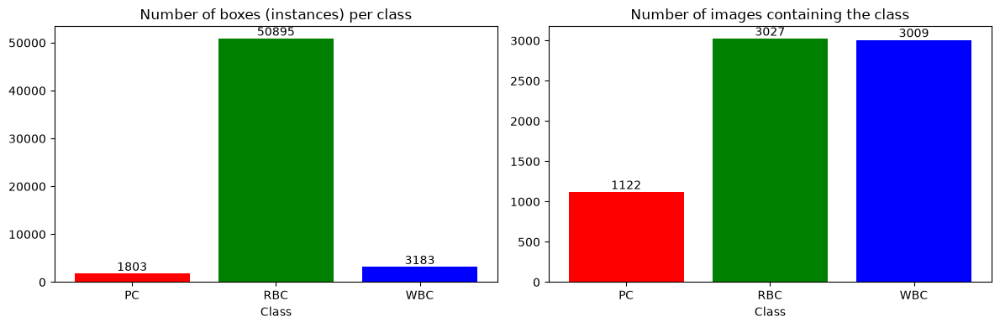

boxes per class: {'RBC': 50895, 'WBC': 3183, 'PC': 1803} | images per class: {'WBC': 3009, 'RBC': 3027, 'PC': 1122}


In [13]:
coco = json.loads((COCO_ROOT / "train" / "_annotations.coco.json").read_text())
cat_name = {c["id"]: c["name"] for c in coco["categories"]}   # look up by id (the list index is NOT the id in general)
print(f"Number of images: {len(coco['images'])}")
print(f"Number of annotations: {len(coco['annotations'])}")

boxes_per_class = Counter(cat_name[a["category_id"]] for a in coco["annotations"])
images_per_class = Counter()
for img_id, cats in pd.DataFrame(coco["annotations"]).groupby("image_id")["category_id"]:
    images_per_class.update({cat_name[c] for c in cats})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, counts, title in [(ax[0], boxes_per_class, "Number of boxes (instances) per class"),
                         (ax[1], images_per_class, "Number of images containing the class")]:
    bars = a.bar(CLASS_NAMES, [counts[c] for c in CLASS_NAMES], color=[CLASS_COLORS[c] for c in CLASS_NAMES])
    a.bar_label(bars); a.set_title(title); a.set_xlabel("Class")
plt.tight_layout(); plt.show()
print("boxes per class:", dict(boxes_per_class), "| images per class:", dict(images_per_class))

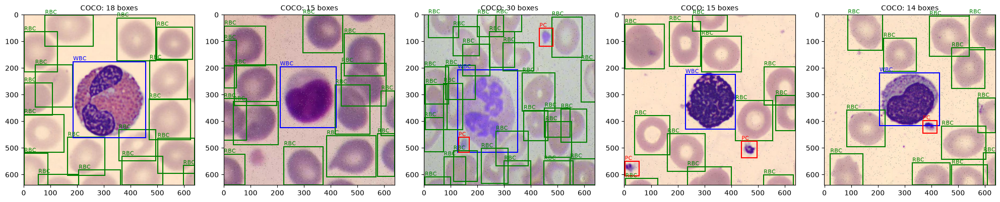

In [14]:
# 5 images with their COCO boxes (same images are reused below for the YOLO version)
N = 5
random.seed(0)
sample_imgs = random.sample(coco["images"], N)
anns_by_img = defaultdict(list)
for a in coco["annotations"]:
    anns_by_img[a["image_id"]].append(a)

fig, axes = plt.subplots(1, N, figsize=(4 * N, 4))
for ax, img in zip(axes, sample_imgs):
    ax.imshow(read_rgb(COCO_ROOT / "train" / img["file_name"]))
    anns = anns_by_img[img["id"]]
    xyxy = [[x, y, x + w, y + h] for x, y, w, h in (a["bbox"] for a in anns)]
    draw_boxes(ax, xyxy, [CLASS_NAMES.index(cat_name[a["category_id"]]) for a in anns])
    ax.set_title(f"COCO: {len(anns)} boxes", fontsize=10)
plt.tight_layout(); plt.show()

### Data exploration — YOLO version

Do the same from the converted `images/` + `labels/` folders. The numbers must match the COCO ones exactly — this is the
check that `coco_to_yolo` is correct.

Number of images: 3027
Number of annotation files: 3027


Number of annotations: 55881


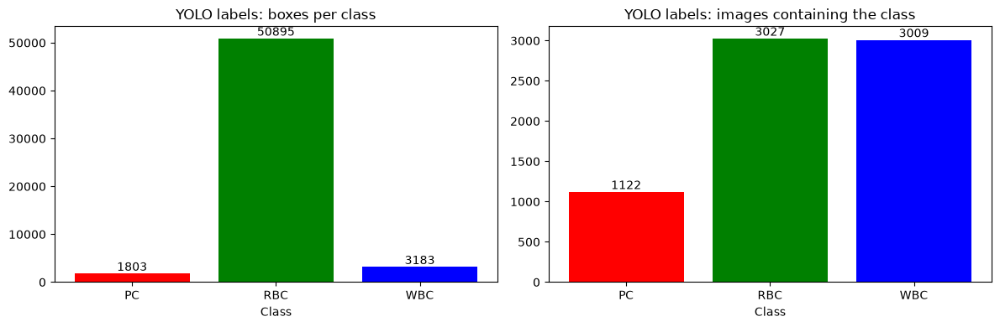

OK: YOLO statistics match the COCO ones


In [15]:
train_images = sorted((YOLO_ROOT / "train" / "images").iterdir())
label_paths = [label_path_for(p) for p in train_images]
print(f"Number of images: {len(train_images)}")
print(f"Number of annotation files: {sum(p.exists() for p in label_paths)}")

yolo_boxes_per_class, yolo_images_per_class = Counter(), Counter()
for lp in label_paths:
    cls, _ = read_yolo_labels(lp, 1, 1)
    yolo_boxes_per_class.update(CLASS_NAMES[c] for c in cls)
    yolo_images_per_class.update({CLASS_NAMES[c] for c in cls})
print(f"Number of annotations: {sum(yolo_boxes_per_class.values())}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, counts, title in [(ax[0], yolo_boxes_per_class, "YOLO labels: boxes per class"),
                         (ax[1], yolo_images_per_class, "YOLO labels: images containing the class")]:
    bars = a.bar(CLASS_NAMES, [counts[c] for c in CLASS_NAMES], color=[CLASS_COLORS[c] for c in CLASS_NAMES])
    a.bar_label(bars); a.set_title(title); a.set_xlabel("Class")
plt.tight_layout(); plt.show()

assert yolo_boxes_per_class == boxes_per_class and yolo_images_per_class == images_per_class, "COCO and YOLO stats differ!"
print("OK: YOLO statistics match the COCO ones")

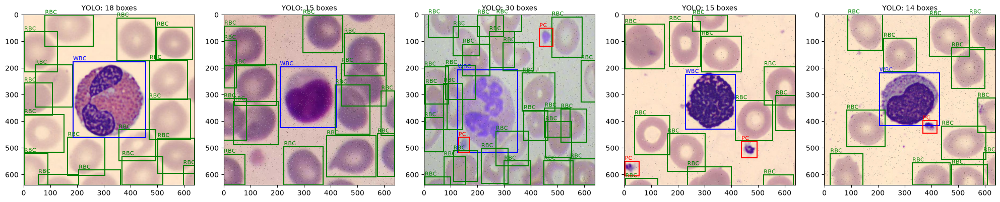

In [16]:
fig, axes = plt.subplots(1, N, figsize=(4 * N, 4))
for ax, img in zip(axes, sample_imgs):
    image_path = YOLO_ROOT / "train" / "images" / img["file_name"]
    image = read_rgb(image_path)
    cls, xyxy = read_yolo_labels(label_path_for(image_path), image.shape[1], image.shape[0])  # de-normalise
    ax.imshow(image)
    draw_boxes(ax, xyxy, cls)
    ax.set_title(f"YOLO: {len(cls)} boxes", fontsize=10)
plt.tight_layout(); plt.show()

**Observations.** The dataset is heavily imbalanced: RBCs are ~90 % of the boxes, while PCs (platelets) are rare *and* tiny,
so PC will be the hardest class. Almost every image has exactly one WBC (the images were cropped around a leukocyte),
and RBCs touching the image border are annotated as partial boxes.

## Customize YOLO (`yolo11n`) model

* `YOLO("yolo11n.yaml")` builds the YOLO11-nano architecture with **random weights** → training *from scratch* (as in the slides).
* `YOLO("yolo11n.pt")` starts from the COCO-pretrained weights → *fine-tuning* (usually converges faster/better; see extras).

In both cases Ultralytics reads `nc: 3` from `data.yaml` and rebuilds the detection head for our 3 classes.

In [17]:
TRAIN_FROM = "scratch"   # "scratch" (yolo11n.yaml, as in the slides) or "pretrained" (yolo11n.pt, fine-tuning)
EPOCHS = 50
BATCH = 16
QUICK_TEST = False       # True -> 1 epoch on 5% of the training images, just to check the pipeline (e.g. on CPU)

RUN_NAME = f"{'from_scratch' if TRAIN_FROM == 'scratch' else 'finetune'}_{EPOCHS}e_v1"
if QUICK_TEST:
    EPOCHS, RUN_NAME = 1, "quick_test"
RUN_DIR = RUNS_DIR / RUN_NAME
SAVED_MODEL = MODELS_DIR / f"blood_cell_yolo11n_{RUN_NAME}.pt"
print(RUN_NAME, "->", SAVED_MODEL)

from_scratch_50e_v1 -> C:\Users\sonia\Documents\master\MasterLabs\CV\models\blood_cell_yolo11n_from_scratch_50e_v1.pt


### Model training

Train settings: https://docs.ultralytics.com/modes/train/#train-settings — `epochs`, `batch`, `imgsz` (640; our images are
already 640×640), `patience` (early stopping), `classes` (train only on a subset of class ids), `plots` (save curves/mosaics).
Results are written to `RUNS_DIR/RUN_NAME` (on Drive when using Colab).

In [18]:
model = YOLO("yolo11n.yaml" if TRAIN_FROM == "scratch" else "yolo11n.pt")

# https://docs.ultralytics.com/modes/train/#train-settings
train_results = model.train(
    data=str(DATA_YAML),
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    epochs=EPOCHS,
    batch=BATCH,
    imgsz=640,
    classes=[0, 1, 2],
    plots=True,
    device=DEVICE,
    seed=0,
    fraction=0.05 if QUICK_TEST else 1.0,
    workers=0 if os.name == "nt" else 8,   # Windows + Jupyter: avoid dataloader worker processes
)

Ultralytics 8.4.216  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4090 Laptop GPU, 16376MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=[0, 1, 2], close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\sonia\Documents\master\MasterLabs\CV\data\blood_cell.v1i.yolov11\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=from_scratch_50e_v1, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (10,146 outputs left out)

                   RBC        288       4879      0.949       0.96      0.988      0.866


                   WBC        286        307      0.989      0.971      0.976      0.856


Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to C:\Users\sonia\Documents\master\MasterLabs\CV\runs\detect\from_scratch_50e_v1


### Save the trained model

In [19]:
best_weights = RUN_DIR / "weights" / "best.pt"   # checkpoint with the best validation fitness (0.1·mAP50 + 0.9·mAP50-95)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
shutil.copy2(best_weights, SAVED_MODEL)
print(f"Saved {best_weights} -> {SAVED_MODEL} ({SAVED_MODEL.stat().st_size / 1e6:.1f} MB)")

Saved C:\Users\sonia\Documents\master\MasterLabs\CV\runs\detect\from_scratch_50e_v1\weights\best.pt -> C:\Users\sonia\Documents\master\MasterLabs\CV\models\blood_cell_yolo11n_from_scratch_50e_v1.pt (5.5 MB)


### Training logs

`RUN_DIR` contains what the slides show: `weights/` (`best.pt`, `last.pt`), `args.yaml`, `results.csv`/`results.png`,
curves, confusion matrices, `labels.jpg` and `train_batch*.jpg`.

* **`train_batch0.jpg`** — the first training batches use **mosaic augmentation** (4 images tiled into one), plus scaling,
  flips and HSV jitter. Labels are drawn with their class **ids** (`0`=PC, `1`=RBC, `2`=WBC).
* **`train_batch7600.jpg`** (later batches) — mosaic is switched off for the last 10 epochs (`close_mosaic=10`), so we see
  single images, letterboxed with grey padding after random scaling/translation.

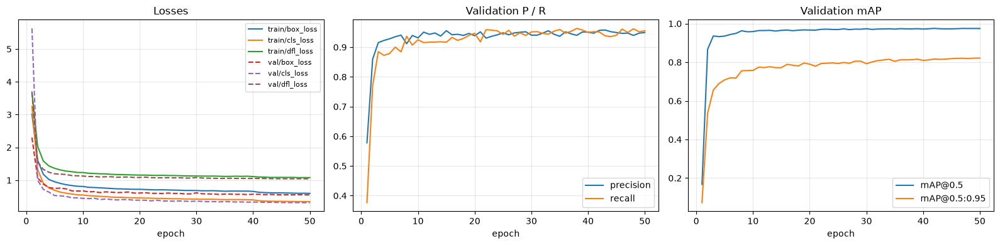

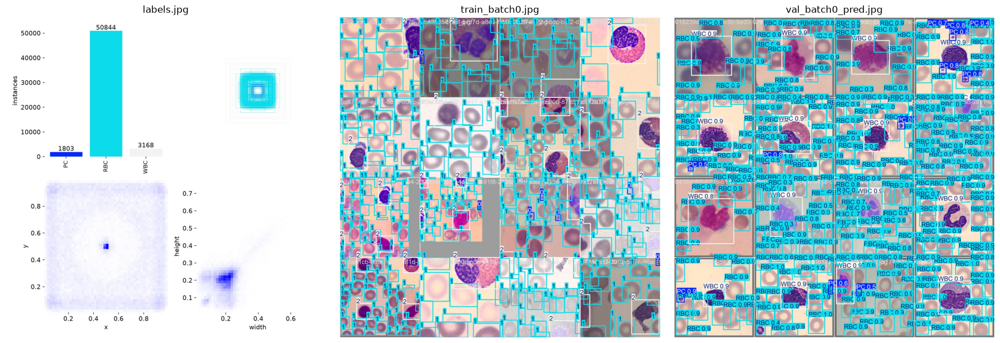

In [20]:
df_log = pd.read_csv(RUN_DIR / "results.csv")
df_log.columns = df_log.columns.str.strip()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for split, ls in [("train", "-"), ("val", "--")]:
    for loss in ["box_loss", "cls_loss", "dfl_loss"]:
        ax[0].plot(df_log["epoch"], df_log[f"{split}/{loss}"], ls, label=f"{split}/{loss}")
ax[0].set_title("Losses"); ax[0].legend(fontsize=8)
ax[1].plot(df_log["epoch"], df_log["metrics/precision(B)"], label="precision")
ax[1].plot(df_log["epoch"], df_log["metrics/recall(B)"], label="recall"); ax[1].set_title("Validation P / R"); ax[1].legend()
ax[2].plot(df_log["epoch"], df_log["metrics/mAP50(B)"], label="mAP@0.5")
ax[2].plot(df_log["epoch"], df_log["metrics/mAP50-95(B)"], label="mAP@0.5:0.95"); ax[2].set_title("Validation mAP"); ax[2].legend()
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, name in zip(ax, ["labels.jpg", "train_batch0.jpg", "val_batch0_pred.jpg"]):
    if (RUN_DIR / name).exists():
        a.imshow(read_rgb(RUN_DIR / name)); a.set_title(name)
    a.axis("off")
plt.tight_layout(); plt.show()

<a id="set-9.3"></a>
# Set 9.3 — Load the pretrained (saved) model and test it on unseen images

The model is loaded back from `MODELS_DIR`, so this section works after a runtime restart: run the *Setup* cells, the
data-preparation cells of 9.2 (unzip + `coco_to_yolo` + `data.yaml`) and the config cell defining `SAVED_MODEL`.
The **test split was never used for training or model selection** (`best.pt` is selected on `valid`).

In [21]:
model = YOLO(SAVED_MODEL)
print("Loaded", SAVED_MODEL, "| classes:", model.names)

Loaded C:\Users\sonia\Documents\master\MasterLabs\CV\models\blood_cell_yolo11n_from_scratch_50e_v1.pt | classes: {0: 'PC', 1: 'RBC', 2: 'WBC'}


### Qualitative evaluation — GT vs prediction

Solid boxes = ground truth, dashed boxes = predictions (with confidence); colour = class (PC red, RBC green, WBC blue).

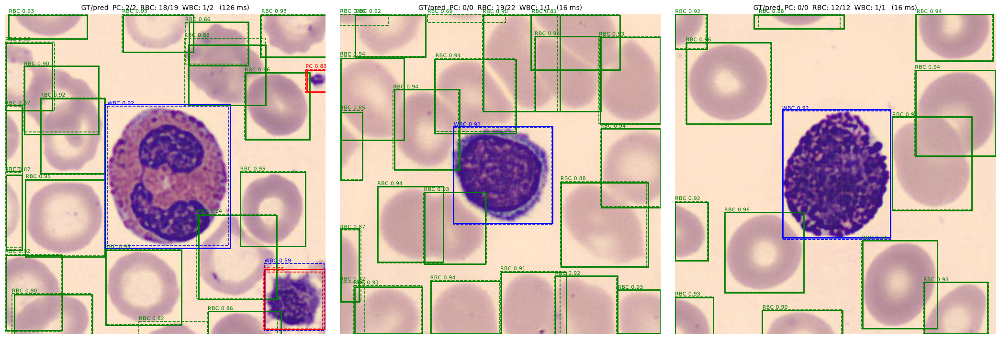

In [22]:
test_images = sorted((YOLO_ROOT / "test" / "images").iterdir())
random.seed(1)
# 3 random unseen images, making sure at least one contains a platelet (the hard class)
with_pc = [p for p in test_images if 0 in read_yolo_labels(label_path_for(p), 1, 1)[0]]
show = random.sample(with_pc, 1) + random.sample([p for p in test_images if p not in with_pc], 2)


def show_gt_vs_pred(image_paths, model, conf=0.25):
    fig, axes = plt.subplots(1, len(image_paths), figsize=(7 * len(image_paths), 7))
    for ax, image_path in zip(np.atleast_1d(axes), image_paths):
        image = read_rgb(image_path)
        gt_cls, gt_xyxy = read_yolo_labels(label_path_for(image_path), image.shape[1], image.shape[0])

        t0 = time.time()
        with torch.no_grad():
            pred = model.predict(str(image_path), conf=conf, device=DEVICE, verbose=False)[0]
        dt = time.time() - t0
        p_cls = pred.boxes.cls.cpu().numpy().astype(int)

        ax.imshow(image)
        draw_boxes(ax, gt_xyxy, gt_cls, lw=2, text=False)
        draw_boxes(ax, pred.boxes.xyxy.cpu().numpy(), p_cls, scores=pred.boxes.conf.cpu().numpy(), ls="--", lw=1.2)
        gt_c, pr_c = Counter(gt_cls.tolist()), Counter(p_cls.tolist())
        counts = "  ".join(f"{n}: {gt_c[i]}/{pr_c[i]}" for i, n in enumerate(CLASS_NAMES))
        ax.set_title(f"GT/pred  {counts}   ({dt * 1000:.0f} ms)", fontsize=10)
        ax.axis("off")
    plt.tight_layout(); plt.show()


show_gt_vs_pred(show, model)

### Quantitative evaluation

* Precision–Recall curve
* False-Positives-Per-Image (FPPI) curve
* Table with mAP@0.5 and mAP@0.5:0.95

First with the built-in Ultralytics validator on the **test** split, then implemented from scratch to understand the metrics.

In [23]:
metrics = model.val(data=str(DATA_YAML), split="test", project=str(RUNS_DIR), name=f"{RUN_NAME}_test",
                    exist_ok=True, plots=True, device=DEVICE)

ultra_table = pd.DataFrame({
    "class": [model.names[i] for i in metrics.box.ap_class_index],
    "P": metrics.box.p, "R": metrics.box.r, "mAP@0.5": metrics.box.ap50, "mAP@0.5:0.95": metrics.box.ap,
})
ultra_table.loc[len(ultra_table)] = ["all", metrics.box.mp, metrics.box.mr, metrics.box.map50, metrics.box.map]
ultra_table.round(3)

Ultralytics 8.4.216  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4090 Laptop GPU, 16376MiB)


YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 78.5±8.9 MB/s, size: 24.4 KB)



val: Scanning C:\Users\sonia\Documents\master\MasterLabs\CV\data\blood_cell.v1i.yolov11\test\labels... 144 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 144/144 1.8Kit/s 0.1s

val: New cache created: C:\Users\sonia\Documents\master\MasterLabs\CV\data\blood_cell.v1i.yolov11\test\labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 11% ━─────────── 1/9 66.6s/it 20.0s<8:53

... (9 outputs left out)

                   WBC        143        148      0.986      0.983      0.989      0.874


Speed: 1.2ms preprocess, 3.1ms inference, 0.0ms loss, 1.6ms postprocess per image


Results saved to C:\Users\sonia\Documents\master\MasterLabs\CV\runs\detect\from_scratch_50e_v1_test


,class,P,R,mAP@0.5,mAP@0.5:0.95
0,PC,0.974,0.901,0.979,0.766
1,RBC,0.963,0.965,0.991,0.881
2,WBC,0.986,0.983,0.989,0.874
3,all,0.974,0.950,0.986,0.840


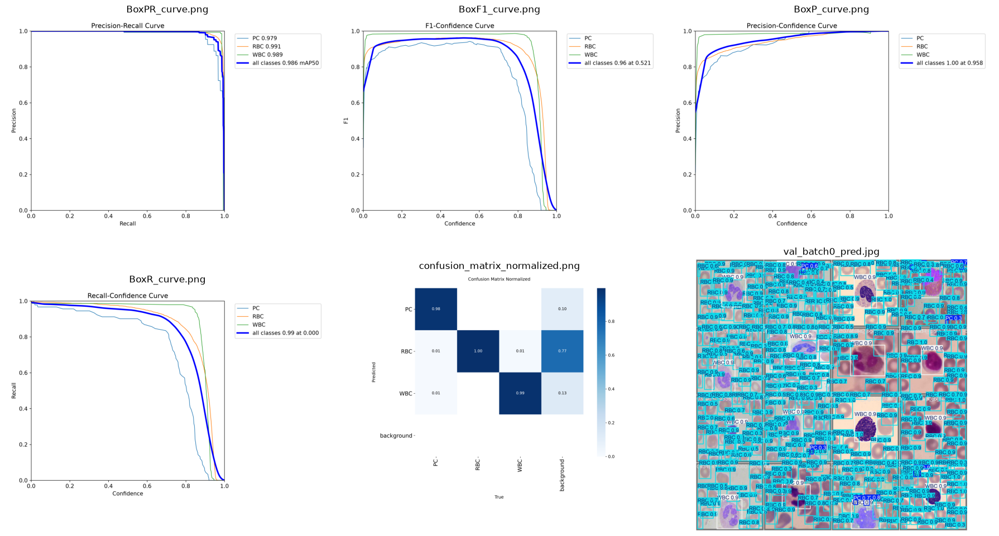

In [24]:
res_path = Path(metrics.save_dir)
plots = ["BoxPR_curve.png", "BoxF1_curve.png", "BoxP_curve.png", "BoxR_curve.png",
         "confusion_matrix_normalized.png", "val_batch0_pred.jpg"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, name in zip(axes.ravel(), plots):
    if (res_path / name).exists():
        ax.imshow(read_rgb(res_path / name))
    ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

#### Metrics from scratch

1. Predict every test image with a very low confidence threshold (`conf=0.001`, like the validator) so the curves cover all
   operating points.
2. For each image and class, sort detections by confidence and **greedily match** each one to the unmatched GT box of the
   **same class** with the highest IoU ≥ threshold → TP, otherwise FP. Repeated for every IoU threshold 0.50, 0.55, …, 0.95.
3. Accumulate over the dataset sorted by confidence: precision = TP/(TP+FP), **recall = TP / #GT boxes** (not / #TP),
   FPPI = FP / #images.
4. AP = area under the interpolated PR curve (COCO-style, 101 recall points); mAP = mean over classes;
   mAP@0.5:0.95 = mean over the 10 IoU thresholds.

(The original notebook re-used the same IoU-0.5 matches for every threshold — hence an identical AP for all IoUs — ignored
the class when matching, and divided recall by the number of TPs.)

In [25]:
IOU_THRS = np.linspace(0.5, 0.95, 10)
trapezoid = getattr(np, "trapezoid", None) or np.trapz


def box_iou(a, b):
    """IoU between every box in a [N,4] and b [M,4] (xyxy) -> [N,M]."""
    tl = np.maximum(a[:, None, :2], b[None, :, :2])
    br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.prod(np.clip(br - tl, 0, None), axis=2)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)


def match_detections(d_xyxy, d_conf, d_cls, gt_xyxy, gt_cls, iou_thrs=IOU_THRS):
    """Greedy, class-aware matching. Returns tp [n_det, n_thr] (bool) and the IoU of each det with its best same-class GT."""
    tp = np.zeros((len(d_xyxy), len(iou_thrs)), bool)
    if len(d_xyxy) == 0 or len(gt_xyxy) == 0:
        return tp, np.zeros(len(d_xyxy))
    ious = box_iou(d_xyxy, gt_xyxy) * (d_cls[:, None] == gt_cls[None, :])   # different class -> IoU 0
    order = np.argsort(-d_conf)
    for t, thr in enumerate(iou_thrs):
        matched = np.zeros(len(gt_xyxy), bool)
        for i in order:                                   # most confident detections pick first
            cand = np.where((ious[i] >= thr) & ~matched)[0]
            if cand.size:
                matched[cand[np.argmax(ious[i, cand])]] = True
                tp[i, t] = True
    return tp, ious.max(axis=1)


def collect_detections(model, image_dir, conf=0.001):
    """Run the model on a folder and return (per-detection DataFrame, #GT per class, #images)."""
    rows, n_gt, n_images = [], Counter(), 0
    for r in model.predict(str(image_dir), stream=True, conf=conf, device=DEVICE, verbose=False):
        H, W = r.orig_shape
        gt_cls, gt_xyxy = read_yolo_labels(label_path_for(r.path), W, H)
        n_gt.update(gt_cls.tolist()); n_images += 1
        d_xyxy = r.boxes.xyxy.cpu().numpy(); d_conf = r.boxes.conf.cpu().numpy()
        d_cls = r.boxes.cls.cpu().numpy().astype(int)
        tp, best_iou = match_detections(d_xyxy, d_conf, d_cls, gt_xyxy, gt_cls)
        for k in range(len(d_conf)):
            rows.append({"image": Path(r.path).name, "cls": d_cls[k], "conf": d_conf[k], "best_iou": best_iou[k],
                         **{f"tp@{thr:.2f}": tp[k, t] for t, thr in enumerate(IOU_THRS)}})
    return pd.DataFrame(rows), n_gt, n_images


def pr_curve(tp, conf, n_gt):
    order = np.argsort(-conf)
    tpc = np.cumsum(tp[order]); fpc = np.cumsum(~tp[order])
    return tpc / max(n_gt, 1), tpc / (tpc + fpc), fpc, conf[order]     # recall, precision, cum. FP, conf


def average_precision(recall, precision):
    """COCO-style AP: precision envelope, 101-point interpolation."""
    mrec = np.concatenate([[0.0], recall, [1.0]])
    mpre = np.concatenate([[1.0], precision, [0.0]])
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    return trapezoid(np.interp(x, mrec, mpre), x)


dets, n_gt, n_test_images = collect_detections(model, YOLO_ROOT / "test" / "images")
print(f"{len(dets)} detections on {n_test_images} images; GT boxes per class:",
      {CLASS_NAMES[c]: n for c, n in sorted(n_gt.items())})
dets.head()

6413 detections on 144 images; GT boxes per class: {'PC': 91, 'RBC': 2439, 'WBC': 148}


,image,cls,conf,best_iou,tp@0.50,tp@0.55,tp@0.60,tp@0.65,tp@0.70,tp@0.75,tp@0.80,tp@0.85,tp@0.90,tp@0.95
0,01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a2...,1,0.942817,0.878621,True,True,True,True,True,True,True,True,False,False
1,01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a2...,1,0.940595,0.905228,True,True,True,True,True,True,True,True,True,False
2,01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a2...,1,0.936296,0.943465,True,True,True,True,True,True,True,True,True,False
3,01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a2...,1,0.935003,0.972048,True,True,True,True,True,True,True,True,True,True
4,01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a2...,1,0.932964,0.941682,True,True,True,True,True,True,True,True,True,False


In [26]:
rows = []
for c, name in enumerate(CLASS_NAMES):
    d = dets[dets["cls"] == c]
    aps = [average_precision(*pr_curve(d[f"tp@{thr:.2f}"].to_numpy(), d["conf"].to_numpy(), n_gt[c])[:2])
           for thr in IOU_THRS]
    rows.append({"class": name, "#GT": n_gt[c], "AP@0.5": aps[0], "AP@0.75": aps[5], "AP@0.5:0.95": np.mean(aps)})
map_table = pd.DataFrame(rows)
map_table.loc[len(map_table)] = ["mAP (mean over classes)", sum(n_gt.values()),
                                 *map_table[["AP@0.5", "AP@0.75", "AP@0.5:0.95"]].mean()]
display(map_table.round(3))
print(f"Ultralytics: mAP@0.5 = {metrics.box.map50:.3f}, mAP@0.5:0.95 = {metrics.box.map:.3f} "
      "(small differences come from details of matching/interpolation)")

,class,#GT,AP@0.5,AP@0.75,AP@0.5:0.95
0,PC,91,0.975,0.909,0.771
1,RBC,2439,0.987,0.953,0.888
2,WBC,148,0.990,0.980,0.894
3,mAP (mean over classes),2678,0.984,0.947,0.851


Ultralytics: mAP@0.5 = 0.986, mAP@0.5:0.95 = 0.840 (small differences come from details of matching/interpolation)


PC: TPR (recall) at 1 FPPI = 1.000
RBC: TPR (recall) at 1 FPPI = 0.956
WBC: TPR (recall) at 1 FPPI = 0.993


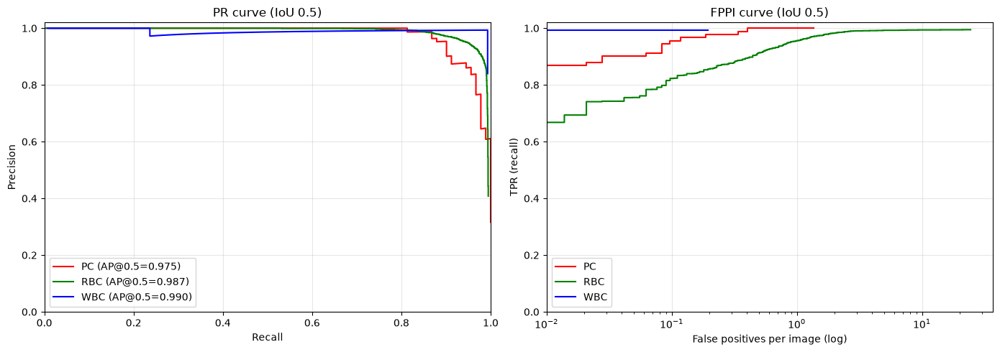

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for c, name in enumerate(CLASS_NAMES):
    d = dets[dets["cls"] == c]
    recall, precision, fpc, _ = pr_curve(d["tp@0.50"].to_numpy(), d["conf"].to_numpy(), n_gt[c])
    ap = average_precision(recall, precision)
    ax[0].plot(recall, precision, color=CLASS_COLORS[name], label=f"{name} (AP@0.5={ap:.3f})")
    ax[1].plot(fpc / n_test_images, recall, color=CLASS_COLORS[name], label=name)
    tpr_at_1 = recall[fpc / n_test_images <= 1].max(initial=0)
    print(f"{name}: TPR (recall) at 1 FPPI = {tpr_at_1:.3f}")
ax[0].set(xlabel="Recall", ylabel="Precision", title="PR curve (IoU 0.5)", xlim=(0, 1), ylim=(0, 1.02))
ax[1].set(xlabel="False positives per image (log)", ylabel="TPR (recall)", title="FPPI curve (IoU 0.5)", xscale="log",
          xlim=(1e-2, None), ylim=(0, 1.02))
for a in ax: a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

**Reading the curves.** All three classes reach AP@0.5 ≥ 0.97 on the test split, so at IoU 0.5 the classes are close:
WBC (0.990) ≈ RBC (0.987) > PC (0.975). WBCs are large and strongly stained and are practically never missed.
PC has the lowest AP@0.5 — its PR curve drops at high recall because of a few low-confidence platelets — but at low FPPI it is
*not* the hardest class: it reaches 100 % recall below 1 FPPI. **RBC** is the class that needs the most false positives per
image to reach high recall (≈ 0.96 at 1 FPPI), since images contain ~17 densely packed, overlapping RBCs, many cut by the border.

The real weakness of PC shows up in **localisation**: AP@0.5:0.95 is 0.77 for PC vs. 0.89 for RBC/WBC. Platelets are tiny
(median box ≈ 50×50 px), so an offset of a few pixels already drops the IoU below 0.75–0.95. Overall mAP@0.5:0.95
(0.84–0.85) is clearly lower than mAP@0.5 (0.98–0.99) for this reason.

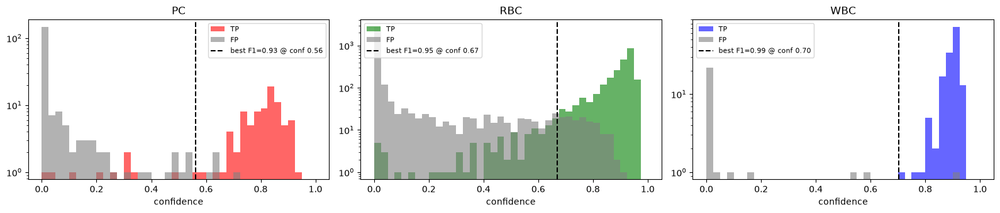

In [28]:
# Confidence histogram of TPs vs FPs (IoU 0.5) and the confidence threshold that maximises F1
fig, ax = plt.subplots(1, len(CLASS_NAMES), figsize=(16, 3.5))
for a, (c, name) in zip(ax, enumerate(CLASS_NAMES)):
    d = dets[dets["cls"] == c]
    if d.empty:
        a.set_title(f"{name}: no detections"); continue
    a.hist(d.loc[d["tp@0.50"], "conf"], bins=40, range=(0, 1), alpha=.6, label="TP", color=CLASS_COLORS[name])
    a.hist(d.loc[~d["tp@0.50"], "conf"], bins=40, range=(0, 1), alpha=.6, label="FP", color="gray")
    recall, precision, _, conf_sorted = pr_curve(d["tp@0.50"].to_numpy(), d["conf"].to_numpy(), n_gt[c])
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    best = np.argmax(f1)
    a.axvline(conf_sorted[best], color="k", ls="--", label=f"best F1={f1[best]:.2f} @ conf {conf_sorted[best]:.2f}")
    a.set_yscale("log"); a.set_title(name); a.set_xlabel("confidence"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

<a id="extras"></a>
# Extras (optional)

Small additions that reuse what is already loaded (`coco`, `model`, `dets`, `YOLO_ROOT`). Each cell is independent.

### E1. Sanity check — our conversion vs. Roboflow's own YOLO export

The same dataset is also available directly in YOLO format (`blood cell.v1i.yolov11.zip`). Comparing label files tells us
whether `coco_to_yolo` matches a reference implementation.

In [29]:
if ROBOFLOW_YOLO_ZIP.exists():
    max_diff, mismatched, n_files = 0.0, [], 0
    with zipfile.ZipFile(ROBOFLOW_YOLO_ZIP) as zf:
        for name in zf.namelist():
            if not (name.endswith(".txt") and "/labels/" in name):
                continue
            ref = sorted(tuple(map(float, l.split())) for l in zf.read(name).decode().splitlines() if l.strip())
            ours_path = YOLO_ROOT / name
            ours = sorted(tuple(map(float, l.split())) for l in ours_path.read_text().splitlines() if l.strip())
            n_files += 1
            if len(ref) != len(ours) or any(a[0] != b[0] for a, b in zip(ref, ours)):
                mismatched.append(name); continue
            if ref:
                ref, ours = np.array(ref), np.array(ours)
                # pair every reference box with the closest box of the same class (line order may differ)
                d = np.abs(ref[:, None, 1:] - ours[None, :, 1:]).max(axis=2)
                d[ref[:, None, 0] != ours[None, :, 0]] = np.inf
                max_diff = max(max_diff, d.min(axis=1).max())
    print(f"{n_files} label files compared, {len(mismatched)} with different #boxes/classes, "
          f"max |coordinate difference| = {max_diff:.2e} (= {max_diff * 640:.1f} px on 640x640 images)")
else:
    print("Roboflow YOLO zip not found, skipping")

3459 label files compared, 0 with different #boxes/classes, max |coordinate difference| = 7.82e-04 (= 0.5 px on 640x640 images)


### E2. Per-class histograms — box size and colour ("histogram per cell")

What makes the classes separable? Box area (log scale) shows a clear size ordering: the median PC box (≈ 2.5k px²) is ~6× smaller
than an RBC (≈ 15k px²) and ~25× smaller than a WBC (≈ 64k px²). The hue histogram of the pixels inside each GT box (HSV, OpenCV
hue ∈ [0,180)) shows the purple-stained WBC nucleus (hue ≈ 125–160) vs. the reddish/pink RBCs (hue near 0 and 165–180).

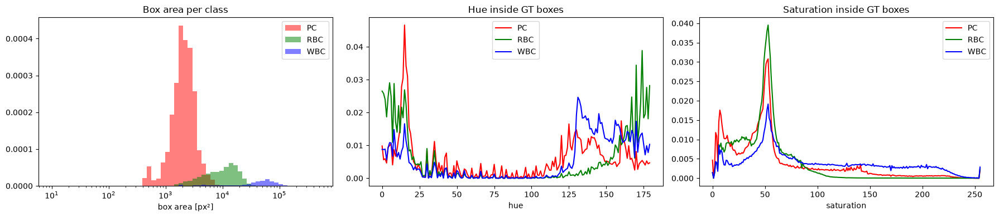

{'PC': 'median area 2500 px²', 'RBC': 'median area 14566 px²', 'WBC': 'median area 63568 px²'}


In [30]:
areas = defaultdict(list)
for a in coco["annotations"]:
    areas[cat_name[a["category_id"]]].append(a["bbox"][2] * a["bbox"][3])

hue_hist = {n: np.zeros(180) for n in CLASS_NAMES}
sat_hist = {n: np.zeros(256) for n in CLASS_NAMES}
random.seed(0)
for img in random.sample(coco["images"], 200):              # 200 images are plenty for the histograms
    hsv = cv2.cvtColor(cv2.imread(str(COCO_ROOT / "train" / img["file_name"])), cv2.COLOR_BGR2HSV)
    for a in anns_by_img[img["id"]]:
        x, y, w, h = map(int, a["bbox"])
        crop = hsv[y:y + h, x:x + w].reshape(-1, 3)
        name = cat_name[a["category_id"]]
        hue_hist[name] += np.bincount(crop[:, 0], minlength=180)[:180]
        sat_hist[name] += np.bincount(crop[:, 1], minlength=256)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for n in CLASS_NAMES:
    ax[0].hist(areas[n], bins=np.logspace(1, 5.7, 60), alpha=.5, color=CLASS_COLORS[n], label=n, density=True)
    ax[1].plot(hue_hist[n] / hue_hist[n].sum(), color=CLASS_COLORS[n], label=n)
    ax[2].plot(sat_hist[n] / sat_hist[n].sum(), color=CLASS_COLORS[n], label=n)
ax[0].set(xscale="log", xlabel="box area [px²]", title="Box area per class")
ax[1].set(xlabel="hue", title="Hue inside GT boxes")
ax[2].set(xlabel="saturation", title="Saturation inside GT boxes")
for a in ax: a.legend()
plt.tight_layout(); plt.show()
print({n: f"median area {np.median(areas[n]):.0f} px²" for n in CLASS_NAMES})

### E3. Cell counting — the clinically relevant output

A blood-smear detector is mostly used to **count** cells (complete blood count). Compare the number of predicted and GT
cells per test image at the operating confidence (0.25).

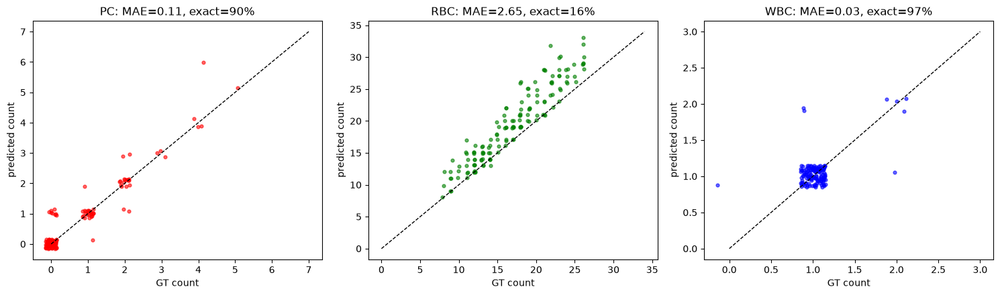

In [31]:
CONF = 0.25
gt_counts = {cls: [] for cls in CLASS_NAMES}; pred_counts = {cls: [] for cls in CLASS_NAMES}
per_image = dets[dets["conf"] >= CONF].groupby(["image", "cls"]).size()
for image_path in test_images:
    gt_cls, _ = read_yolo_labels(label_path_for(image_path), 1, 1)
    for c, n in enumerate(CLASS_NAMES):
        gt_counts[n].append(int((gt_cls == c).sum()))
        pred_counts[n].append(int(per_image.get((image_path.name, c), 0)))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, n in zip(ax, CLASS_NAMES):
    g, p = np.array(gt_counts[n]), np.array(pred_counts[n])
    jitter = np.random.default_rng(0).uniform(-.15, .15, size=(2, len(g)))
    a.scatter(g + jitter[0], p + jitter[1], s=12, alpha=.6, color=CLASS_COLORS[n])
    lim = max(g.max(), p.max()) + 1
    a.plot([0, lim], [0, lim], "k--", lw=1)
    a.set(xlabel="GT count", ylabel="predicted count", title=f"{n}: MAE={np.abs(g - p).mean():.2f}, "
          f"exact={np.mean(g == p):.0%}")
plt.tight_layout(); plt.show()

### E4. Activation map — where does the detector look?

A gradient-free activation map: take a feature map `A` (C × h × w) from inside the network, reshape it to an (h·w) × C
matrix and project it onto its dominant direction (first principal component, via SVD). The result is the main spatial
activation pattern of that layer, upsampled and overlaid on the image. We hook a neck layer of the YOLO model (layer 16 = the stride-8 P3 feature map, used for small objects like PCs).

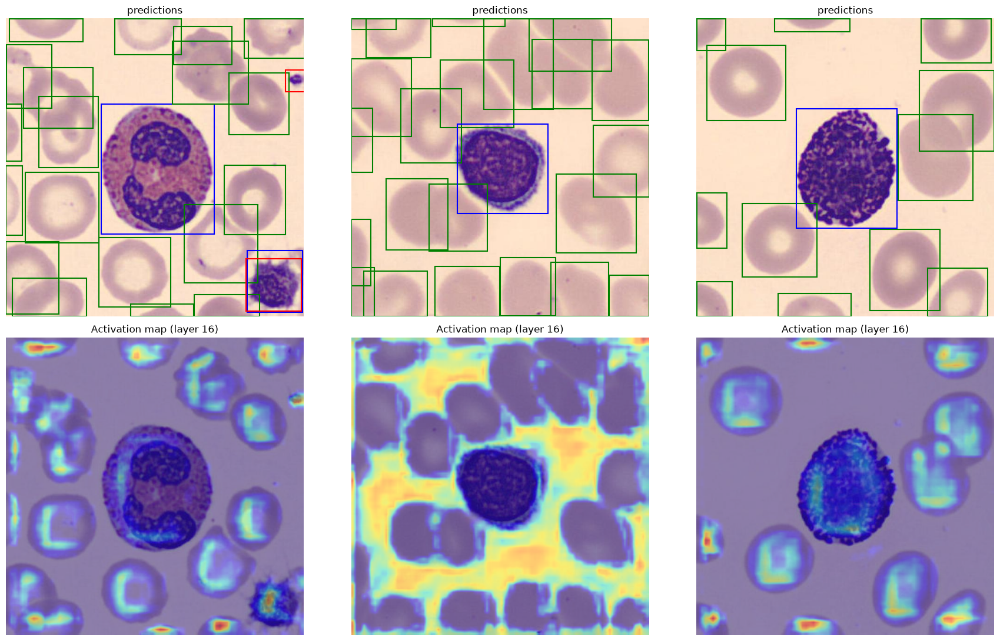

In [32]:
def activation_map(model, image_path, layer_idx=16):
    feats = {}
    if model.predictor is None:                                 # predict() runs a (fused) copy of the network that
        model.predict(str(image_path), device=DEVICE, verbose=False)   # lives in model.predictor -> hook that copy
    layer = model.predictor.model.model.model[layer_idx]
    handle = layer.register_forward_hook(lambda m, i, o: feats.__setitem__("A", o.detach()))
    try:
        pred = model.predict(str(image_path), conf=0.25, device=DEVICE, verbose=False)[0]
    finally:
        handle.remove()
    A = feats["A"][0].float().cpu().numpy()                     # C x h x w
    C, h, w = A.shape
    M = A.reshape(C, -1).T                                      # (h*w) x C
    M = M - M.mean(axis=0)
    _, _, Vt = np.linalg.svd(M, full_matrices=False)
    cam = (M @ Vt[0]).reshape(h, w)
    cam = cam if cam.sum() >= 0 else -cam                       # the sign of the principal direction is arbitrary
    cam = np.maximum(cam, 0); cam /= cam.max() + 1e-9
    return pred, cam


fig, axes = plt.subplots(2, len(show), figsize=(6 * len(show), 11))
for k, image_path in enumerate(show):
    image = read_rgb(image_path)
    pred, cam = activation_map(model, image_path)
    axes[0, k].imshow(image)
    draw_boxes(axes[0, k], pred.boxes.xyxy.cpu().numpy(), pred.boxes.cls.cpu().numpy().astype(int), text=False)
    axes[1, k].imshow(image)
    axes[1, k].imshow(cv2.resize(cam, (image.shape[1], image.shape[0])), cmap="jet", alpha=.45)
    axes[0, k].set_title("predictions"); axes[1, k].set_title("Activation map (layer 16)")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()